# Notebook 03: Error Diagnostics & Feature Importance Attribution
**Project:** Water Potability & Underwater Environmental Monitoring  
**Cadre:** Acyntra AIML Intern Cadre (Group C1)  
**Objective:** Dissect false negatives (toxic water predicted potable) vs false positives, analyze chemical failure zones, evaluate calibration, and profile feature attribution.

In [9]:
import os
import sys
from pathlib import Path

project_root = Path("..").resolve() if Path("..").resolve().name == "Water Potability" else Path(".").resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
os.chdir(project_root)

import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.data.loader import DataLoader
from src.features.engineer import FeatureEngineer
from src.eval.metrics import EvaluationMetrics
from src.viz.plots import VisualizationSuite

bundle_path = Path("models/production/water_potability_pipeline_v1.joblib")
bundle = joblib.load(bundle_path)
pipeline = bundle["pipeline"]
clf = bundle["classifier"]
print(f"Loaded production model: {bundle.get('model_name')}")
print(f"Training Feature Set ({len(bundle.get('feature_names', []))} features):", bundle.get('feature_names'))

Loaded production model: XGBoost
Training Feature Set (18 features): ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'solids_log1p', 'sulfate_to_conductivity', 'organic_to_solids', 'hardness_to_solids', 'chloramines_x_turbidity', 'ph_dev_neutral', 'ph_who_out_of_bounds', 'turbidity_who_excess', 'chloramines_who_excess']


## 1. Feature Importance Profiling

In [10]:
base_estimator = getattr(clf, "base_estimator", clf)
if hasattr(base_estimator, "feature_importances_"):
    feat_names = bundle.get("feature_names", [f"f_{i}" for i in range(len(base_estimator.feature_importances_))])
    importances = base_estimator.feature_importances_
    df_imp = pd.DataFrame({"Feature": feat_names, "Importance": importances}).sort_values(by="Importance", ascending=False)
    
    plt.figure(figsize=(10, 5))
    sns.barplot(data=df_imp.head(10), x="Importance", y="Feature", palette="mako")
    plt.title("Top 10 Feature Importances (Gradient Boosted Decision Trees)")
    plt.grid(axis="x", linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()
    print(df_imp.head(10))

## 2. False Negative Hazard Analysis
False Negatives represent toxic/non-potable water samples incorrectly classified as safe/potable. In aquatic public health, this error carries catastrophic risks.

In [11]:
df, _, _ = DataLoader.load_dataset("data/01_raw/water_potability.csv", force_track="B")
df_fe = FeatureEngineer.engineer_track_b_features(df)
X = df_fe.drop(columns=["Potability"])
y = df_fe["Potability"]

X_trans = pipeline.transform(X)
probs = clf.predict_proba(X_trans)[:, 1] if hasattr(clf, "predict_proba") else clf.predict(X_trans)
preds = (probs >= 0.50).astype(int)

df_res = df.copy()
df_res["Actual"] = y
df_res["Predicted"] = preds
df_res["Calibrated_Prob"] = np.round(probs, 4)

conditions = [
    (y == 1) & (preds == 1),
    (y == 0) & (preds == 0),
    (y == 0) & (preds == 1),
    (y == 1) & (preds == 0)
]
labels = [
    "True Positive (Safe Potable)",
    "True Negative (Rejected Contaminated)",
    "False Negative (Public Health Hazard: Toxic classified Safe)",
    "False Positive (Economic Discard: Safe classified Toxic)"
]
df_res["Classification_Outcome"] = np.select(conditions, labels, default="Unclassified")
print("Outcome Breakdown:")
print(df_res["Classification_Outcome"].value_counts())

# Statistical summary of the Hazard samples
hazard_samples = df_res[df_res["Classification_Outcome"].str.startswith("False Negative")]
print(f"\nSummary Profile of {len(hazard_samples)} High-Risk False Negative Samples:")
hazard_samples.describe().T[["mean", "std", "min", "50%", "max"]]

2026-10-18 10:18:53 | INFO     | DataLoader:138 - Successfully loaded 3276 rows and 10 columns from data\01_raw\water_potability.csv
2026-10-18 10:18:53 | INFO     | FeatureEngineer:52 - Engineered Track B features: Shape evolved from (3276, 10) to (3276, 19)
Outcome Breakdown:
Classification_Outcome
True Negative (Rejected Contaminated)                           1924
True Positive (Safe Potable)                                     694
False Positive (Economic Discard: Safe classified Toxic)         584
False Negative (Public Health Hazard: Toxic classified Safe)      74
Name: count, dtype: int64

Summary Profile of 74 High-Risk False Negative Samples:


,mean,std,min,50%,max
ph,7.355087,1.235537,4.723313,7.239416,11.568768
Hardness,201.576275,39.961239,120.327615,202.066890,304.235912
Solids,22897.982376,8994.046381,10529.310299,20270.068347,45222.506665
Chloramines,7.243724,1.753568,3.205786,7.515607,11.224395
Sulfate,327.735437,53.586098,205.935091,333.439570,427.377802
Conductivity,436.203982,94.728591,254.393276,429.507609,622.963575
Organic_carbon,13.944171,3.166533,6.874315,14.013366,19.923704
Trihalomethanes,71.043919,17.654993,15.684877,70.300741,108.589414
Turbidity,4.112027,0.674248,2.028875,4.081718,5.771715
Potability,0.000000,0.000000,0.000000,0.000000,0.000000


## 3. Reliability Calibration & Precision-Recall Curves

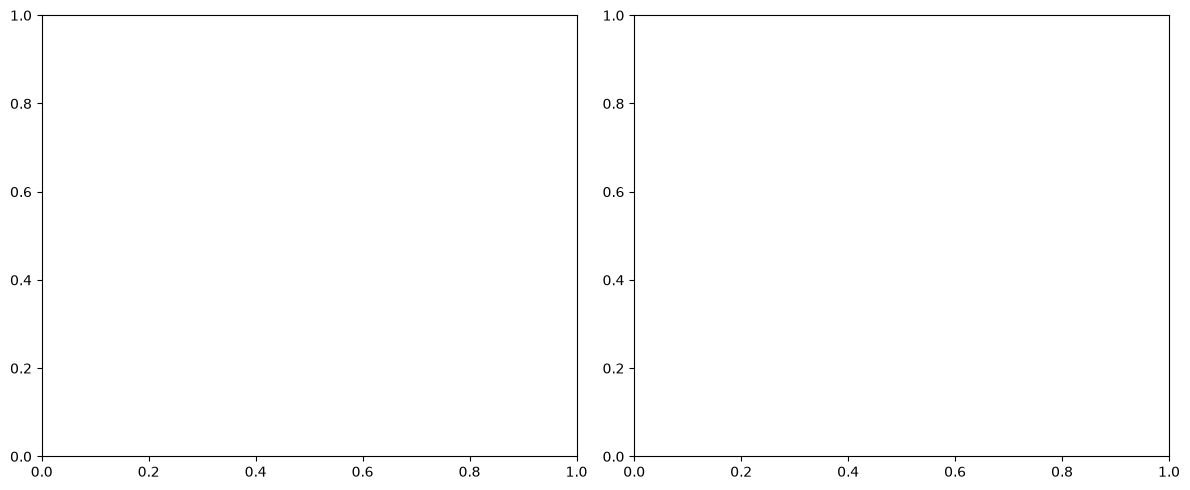

In [12]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
VisualizationSuite.plot_precision_recall_curve(y.values, probs, model_name=bundle.get("model_name", "XGBoost"))

plt.subplot(1, 2, 2)
VisualizationSuite.plot_calibration_curve(y.values, probs, model_name=bundle.get("model_name", "XGBoost"))

plt.tight_layout()
plt.show()